# 비스듬한 종이 사진을 반듯한 스캔본으로

책상 위 종이를 휴대폰으로 찍으면 종이가 비스듬한 사다리꼴로 찍힌다. 이 노트북은 그런 사진을 **반듯한 흑백 스캔본**으로 바꾸는 스캐너를 OpenCV로 만든다. 그리고 사진 20장으로 시험해 **사람이 정한 규칙만으로 어디까지 되는지** 확인한다. 딥러닝은 쓰지 않는다.

| 부 | 보여 주는 것 |
| --- | --- |
| 0 | 결과 먼저: 사진 한 장이 스캔본이 되는 모습 |
| 1 | 다섯 단계: 사진 한 장(E01)을 단계별로 따라가며, 단계마다 "이 단계를 빼면?"을 그림으로 비교한다 |
| 2 | 한 줄로 부르기: 다섯 단계를 묶은 `scan()`과 앱의 다섯 창, 설정 손잡이 |
| 3 | 20장 성적: 정답 꼭짓점과 비교해 성공·실패를 센다 |
| 4 | 한계: 설정 266가지와 대책 규칙을 써도 풀리지 않는 사진 |

**실행 준비.** A3-1 폴더에서 `uv sync`를 한 번 실행하고, 만들어진 `.venv`의 Python을 노트북 커널로 고른다. 셀을 위에서부터 차례로 실행한다. 그림 속 글자는 영어로 두고 본문에서 한국어로 풀어 준다.

In [1]:
# ── 도구 불러오기 ──
from pathlib import Path
import sys
from dataclasses import replace      # 설정 묶음에서 값 하나만 바꾼 사본을 만든다 (2부부터)

import cv2                           # OpenCV: 사진 처리 함수 모음
import numpy as np                   # NumPy: 숫자 표(배열) 계산
import matplotlib.pyplot as plt      # 그래프

# 노트북을 notebooks 폴더에서 열었으면 한 칸 위(A3-1 폴더)를 기준으로 삼는다.
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if not (root / 'src/scanner.py').is_file():
    raise FileNotFoundError('A3-1 폴더 또는 그 안의 notebooks 폴더에서 실행해 주세요.')
sys.path.insert(0, str(root))

from src import scanner, geometry, evaluate            # 미션에서 만든 스캐너·채점 코드
from src.image_io import imread                        # 사진 파일을 숫자 표(배열)로 읽는 함수
from src.nbview import table, show_images, show_grid   # 표·그림을 띄우는 도우미 (계산은 없다)

cv2.setNumThreads(2)   # 컴퓨터가 달라도 비슷하게 동작하도록 OpenCV의 일꾼(스레드) 수를 고정한다
print('OpenCV', cv2.__version__, '/ NumPy', np.__version__)

OpenCV 5.0.0 / NumPy 2.5.4


## 0. 결과 먼저

아래 셀이 이 노트북의 목표다. 왼쪽 사진을 넣으면 오른쪽 스캔본이 나온다. `scanner.scan()`은 1부의 다섯 단계를 한 번에 해 주는 함수다. 1부에서 그 안을 한 단계씩 연다.

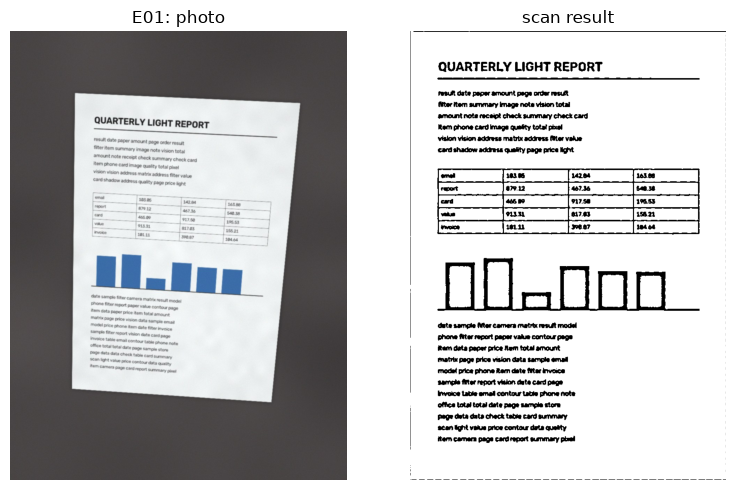

In [2]:
image = imread(root / 'data/synthetic/E01.jpg')   # 회색 책상 위 A4 보고서 사진
result = scanner.scan(image)                       # 다섯 단계를 한 번에
show_images([('E01: photo', image), ('scan result', result.scanned)], columns=2, height=5)

## 1부. 다섯 단계

| 단계 | 하는 일 | 풀어 주는 문제 |
| --- | --- | --- |
| 1 | 줄이고, 흑백으로, 흐리게 | 큰 사진·색·잡티는 경계 찾기를 방해한다 |
| 2 | 경계선을 찾고 끊긴 곳을 잇는다 | 종이 테두리를 선으로 뽑아야 한다 |
| 3 | 선 덩어리 중에서 종이를 고른다 | 선은 글자에도, 표에도 있다 |
| 4 | 꼭짓점 순서를 정하고 직사각형으로 편다 | 그냥 잘라 내면 여전히 비스듬하다 |
| 5 | 흑백 두 색으로 만든다 | 그림자가 있어도 글자가 보여야 한다 |

### 단계 1. 줄이고, 흑백으로, 흐리게

**풀 문제.** 종이를 찾는다는 것은 **종이와 책상의 경계**를 찾는다는 뜻이다. 경계는 밝기가 갑자기 바뀌는 곳이다.

**컴퓨터에게 사진은 숫자 표다.** 사진은 작은 점(픽셀)이 가로세로로 늘어선 것이다. 흑백이라면 점 하나가 밝기 숫자 하나다. 0은 검정, 255는 흰색이다. 종이 왼쪽 위 모서리 근처 10×10칸을 숫자로 본다.

사진의 크기 (세로, 가로, 색 수): (1280, 960, 3)


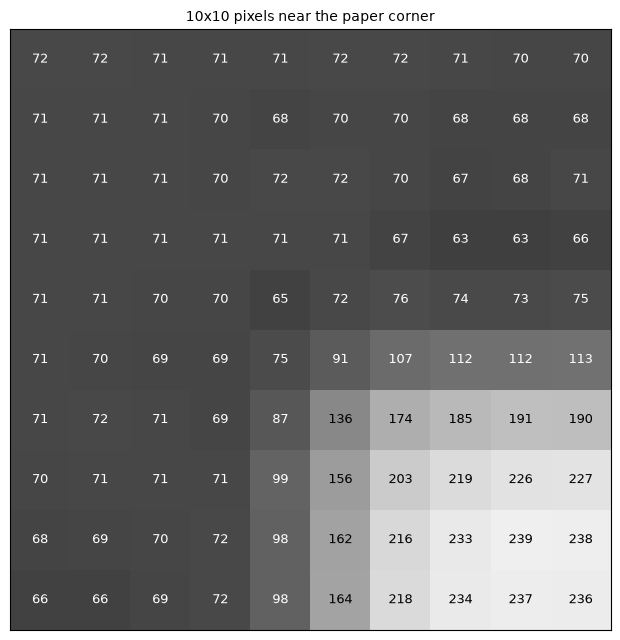

In [3]:
# 흑백으로 바꾼 뒤 종이 왼쪽 위 모서리 근처를 잘라 본다. 배열은 [세로 범위, 가로 범위] 순서로 자른다.
gray_full = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print('사진의 크기 (세로, 가로, 색 수):', image.shape)
show_grid('10x10 pixels near the paper corner', gray_full[170:180, 180:190])

**출력 읽기.** 사진은 세로 1280점, 가로 960점이고 점마다 색 숫자가 3개(파랑·초록·빨강)다. 숫자 그림의 위쪽과 왼쪽에 있는 60–70대 값은 어두운 책상이고, 오른쪽 아래의 200을 넘는 값은 흰 종이다. 그 사이에서 숫자가 크게 뛰는 곳이 우리가 찾을 경계다.

경계를 찾기 전에 사진을 세 가지로 다듬는다.

- **줄이기.** 긴 쪽을 960점으로 줄인다. 계산이 빨라지고 종이 결 같은 자잘한 무늬가 줄어든다. 몇 배 줄였는지(`scale`)는 기억해 두었다가 단계 4에서 되돌린다.
- **흑백.** 색 숫자 3개를 밝기 1개로 합친다. 사람 눈이 가장 밝게 느끼는 초록에 가장 큰 몫(0.587)을 준다.
- **블러(흐리게).** 각 점을 이웃 점들과 섞는다. 가까운 이웃일수록 큰 몫을 주는 종 모양(가우시안)의 5×5 몫 표를 쓴다. 이 몫 표를 **커널**이라고 부른다. 혼자 튀는 잡티는 이웃과 섞여 가라앉는다.

원본 (1280, 960, 3) → 작은 사본 (960, 720, 3) / scale = 0.75


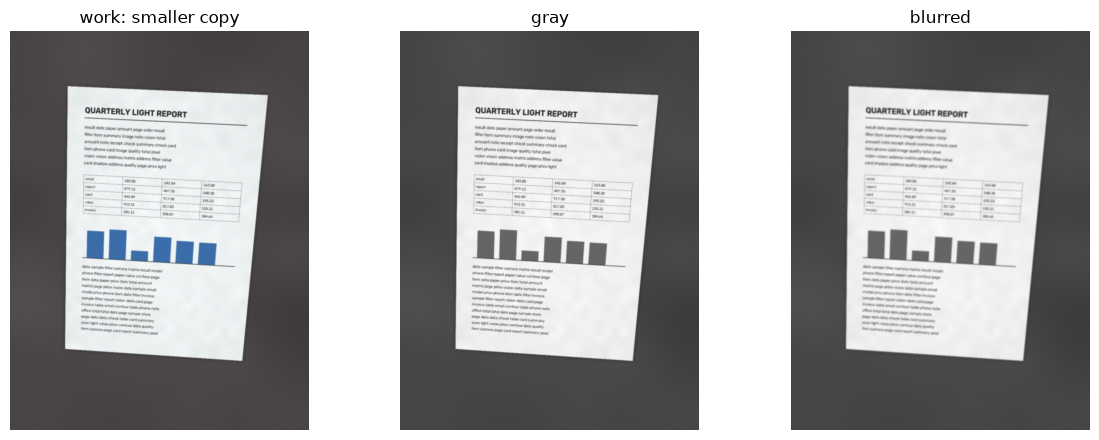

In [4]:
height, width = image.shape[:2]                  # shape는 (세로, 가로, 색 수) 순서
scale = min(1.0, 960 / max(height, width))       # 긴 쪽을 960으로: 960 / 1280 = 0.75
# cv2.resize에 주는 크기는 (가로, 세로) 순서다. shape와 반대다.
work = cv2.resize(image, (round(width * scale), round(height * scale)), interpolation=cv2.INTER_AREA)

gray = cv2.cvtColor(work, cv2.COLOR_BGR2GRAY)    # 밝기 = 0.114·파랑 + 0.587·초록 + 0.299·빨강
blurred = cv2.GaussianBlur(gray, (5, 5), 0)      # 5×5 가우시안 블러. 0은 "퍼지는 정도는 크기에 맞춰 자동"

print('원본', image.shape, '→ 작은 사본', work.shape, '/ scale =', scale)
show_images([('work: smaller copy', work), ('gray', gray), ('blurred', blurred)], columns=3, height=4.5)

**블러를 빼면?** 그림자가 진하게 걸친 사진 S03에서, 블러 없이 찾은 경계선과 블러한 뒤 찾은 경계선을 비교한다. 경계선 찾기(`cv2.Canny`)는 바로 다음 단계에서 설명한다.

경계선 위의 점 수: 블러 없이 23466 / 블러 뒤 11503


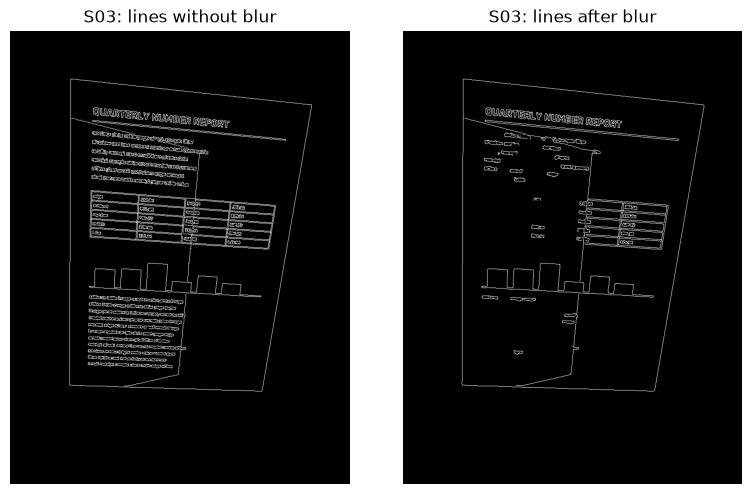

In [5]:
s03 = imread(root / 'data/synthetic/S03.jpg')
s03_gray = cv2.cvtColor(cv2.resize(s03, (720, 960), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)

lines_without_blur = cv2.Canny(s03_gray, 50, 150)
lines_after_blur = cv2.Canny(cv2.GaussianBlur(s03_gray, (5, 5), 0), 50, 150)

# np.count_nonzero는 0이 아닌 칸의 수를 센다. 경계선 위의 점만 0이 아니다.
print('경계선 위의 점 수: 블러 없이', np.count_nonzero(lines_without_blur),
      '/ 블러 뒤', np.count_nonzero(lines_after_blur))
show_images([('S03: lines without blur', lines_without_blur),
             ('S03: lines after blur', lines_after_blur)], columns=2, height=5)

**출력 읽기.** 블러 없이는 경계선 점이 약 2배다. 왼쪽 그림(without blur)에는 본문의 작은 글자 줄이 모두 선으로 잡혔다. 오른쪽(after blur)에서는 대부분 사라졌고, 종이 테두리·표·그림자의 경계처럼 뚜렷한 선만 남았다. 블러는 **뚜렷한 테두리는 남기고 자잘한 선을 줄인다.** 다만 너무 세게 흐리면 약한 테두리까지 뭉개진다는 것을 4부에서 본다.

### 단계 2. 경계선 찾기, 끊긴 선 잇기

**풀 문제.** `blurred`는 아직 밝기 표다. 다음 단계에서 "이 선이 사각형인가"를 따지려면 **종이 테두리를 따라 그은 선**이 필요하다.

**경계 = 밝기가 가파르게 바뀌는 곳.** 작은 사본의 300번째 줄을 왼쪽에서 오른쪽으로 따라가며 밝기를 그래프로 그린다.

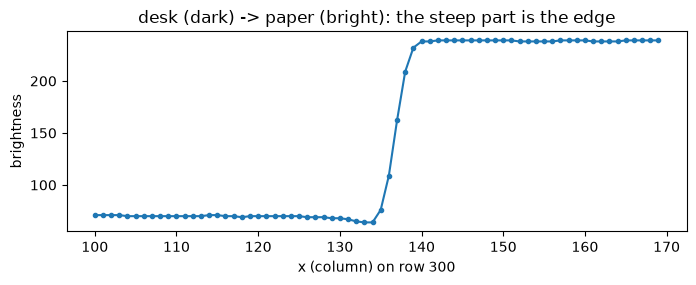

In [6]:
xs = np.arange(100, 170)                         # 가로 100–169번 칸. 종이의 왼쪽 테두리가 이 안에 있다
fig, axis = plt.subplots(figsize=(8, 2.6))
axis.plot(xs, blurred[300, 100:170], marker='.')
axis.set_xlabel('x (column) on row 300')
axis.set_ylabel('brightness')
axis.set_title('desk (dark) -> paper (bright): the steep part is the edge')
plt.show()

**출력 읽기.** 70 안팎에 머물던 밝기가 다섯 칸 남짓 사이에 230대로 뛰어오른다. 이 가파른 곳이 종이의 왼쪽 테두리다. 옆 칸과의 밝기 차이, 곧 이 오르막의 가파른 정도를 **기울기**라고 부른다.

**Canny**(이 방법을 만든 사람의 이름)는 모든 점에서 기울기를 재고, 선을 한 점 두께로 얇게 만든 뒤, **기준 숫자(임계값) 두 개**로 거른다.

- 기울기가 `high`(150)보다 크면 확실한 경계선이다.
- `low`(50)보다 작으면 버린다.
- 그 사이면 확실한 경계선과 **이어져 있을 때만** 남긴다.

**닫힘(closing).** Canny가 찾은 테두리에는 한두 칸짜리 틈이 생길 수 있다. 틈이 있으면 다음 단계에서 "닫힌 도형"으로 인정받지 못한다. 그래서 흰 선을 한 칸씩 두껍게 했다가(팽창) 다시 깎는다(침식). 선은 원래 두께로 돌아오고, 메워진 틈은 메워진 채로 남는다.

경계선 위의 점 수: 20191 → 닫힘 뒤 30800


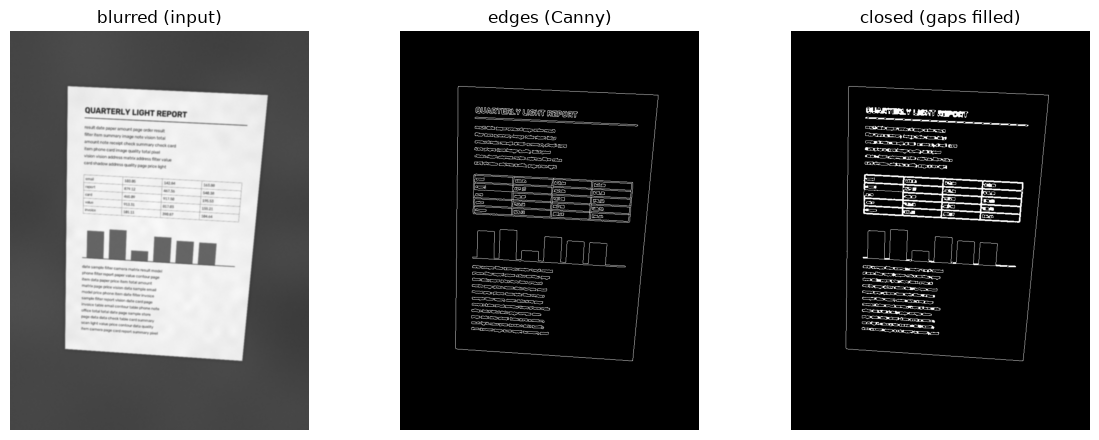

In [7]:
edges = cv2.Canny(blurred, 50, 150)                                           # low 50, high 150
closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))   # 3×3 크기로 닫힘

print('경계선 위의 점 수:', np.count_nonzero(edges), '→ 닫힘 뒤', np.count_nonzero(closed))
show_images([('blurred (input)', blurred), ('edges (Canny)', edges), ('closed (gaps filled)', closed)],
            columns=3, height=4.5)

**기준이 왜 두 개인가?** 높은 기준 하나만 쓴 결과(`Canny(…, 150, 150)`)와 비교한다. 종이 안의 표 부분을 크게 잘라 본다.

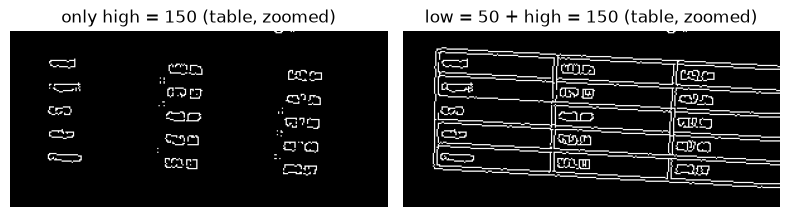

In [8]:
only_high = cv2.Canny(blurred, 150, 150)
show_images([('only high = 150 (table, zoomed)', only_high[330:470, 150:450]),
             ('low = 50 + high = 150 (table, zoomed)', edges[330:470, 150:450])], columns=2, height=2.6)

**출력 읽기.** 왼쪽(only high)에서는 표의 옅은 줄이 대부분 사라졌다. 줄이 옅어서 기울기가 150에 못 미치는 곳이 많기 때문이다. 오른쪽에서는 줄이 살아 있다. 줄의 일부만 150을 넘어도 거기에 이어진 약한 부분이 함께 남는다. 두 기준을 함께 쓰면 **선은 끊기지 않게 잇고, 외톨이 잡티는 버린다.**

**닫힘을 빼면?** 명함 사진 E03으로 본다. 닫힘 크기를 0으로 주면 닫힘을 끈다.

닫힘 있음 → 찾았나? True
닫힘 없음 → 찾았나? False / 이유: 면적 조건을 만족하는 닫힌 윤곽선 없음


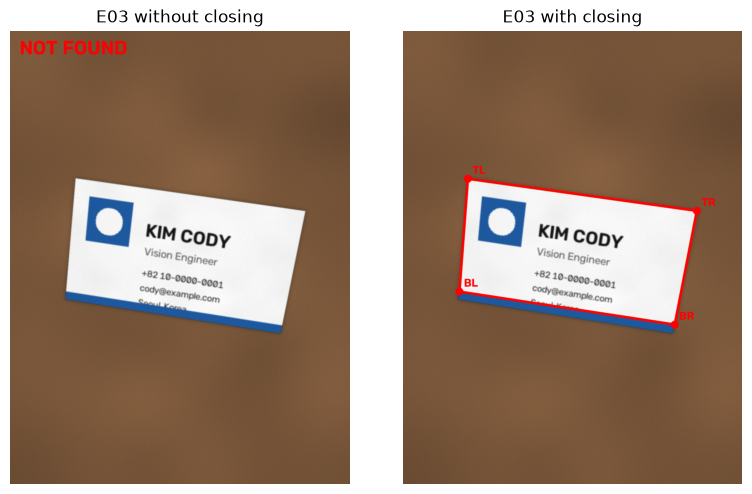

In [9]:
card = imread(root / 'data/synthetic/E03.jpg')
card_with_closing = scanner.scan(card)
card_without_closing = scanner.scan(card, scanner.ScanParams(close_kernel=0))

print('닫힘 있음 → 찾았나?', card_with_closing.found)
print('닫힘 없음 → 찾았나?', card_without_closing.found, '/ 이유:', card_without_closing.reason)
# draw_contours는 작은 사본 위에 찾은 사각형(빨강)을 그린다. 못 찾으면 NOT FOUND라고 적는다.
show_images([('E03 without closing', scanner.draw_contours(card_without_closing)),
             ('E03 with closing', scanner.draw_contours(card_with_closing))], columns=2, height=5)

**출력 읽기.** 닫힘 없이는 명함을 못 찾는다. 명함 테두리 어딘가가 한두 칸 끊겨 "명함 전체를 둘러싼 닫힌 덩어리"가 생기지 않았다. 닫힘으로 틈을 메우자 찾았다. 다만 오른쪽 그림의 빨간 사각형은 명함 아래쪽 파란 띠를 빼고 흰 부분만 감쌌다. 이 문제는 3부와 4부에서 다시 나온다.

### 단계 3. 선 덩어리 중에서 종이 고르기

**풀 문제.** `closed`는 흰 점이 3만 개쯤 찍힌 그림이다. 필요한 것은 **종이의 네 꼭짓점 좌표**다. 먼저 서로 이어진 흰 점들을 한 덩어리로 묶고, 덩어리마다 테두리를 점 목록으로 뽑는다. 이 점 목록을 **윤곽선(contour)** 이라고 부른다.

윤곽선 수: 374


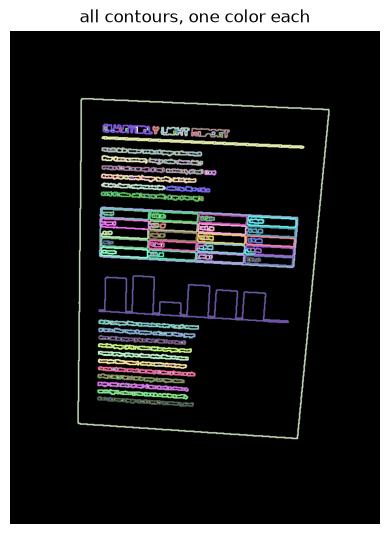

In [10]:
# 이어진 흰 점 덩어리마다 테두리를 점 목록(윤곽선)으로 뽑는다. 둘째 값(덩어리끼리의 관계)은 쓰지 않는다.
contours, _ = cv2.findContours(closed, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
print('윤곽선 수:', len(contours))

# 윤곽선마다 다른 색으로 그려 본다.
rng = np.random.default_rng(0)
all_contours = np.zeros_like(work)
for contour in contours:
    color = [int(v) for v in rng.integers(80, 256, 3)]
    cv2.drawContours(all_contours, [contour], -1, color, 2)
show_images([('all contours, one color each', all_contours)], columns=1, height=6)

**출력 읽기.** 윤곽선이 수백 개다. 글자 하나하나, 표의 칸, 막대, 그리고 종이 테두리가 모두 들어 있다. 이 가운데 종이를 사람이 정한 **규칙 네 개**로 고른다.

| 규칙 | 내용 | 걸러 내려는 것 |
| --- | --- | --- |
| 1. 넓이 | 화면 넓이의 5%보다 크고 98%보다 작다 | 글자 같은 작은 덩어리, 사진 테두리 전체 |
| 2. 꼭짓점 4개 | 둘레의 2%보다 작은 굴곡을 무시하고 다듬으면 꼭짓점이 4개다 | 둥글거나 울퉁불퉁한 모양 |
| 3. 볼록 | 안으로 꺾인 곳이 없다 | 움푹 들어간 사각형 |
| 4. 가장 큰 것 | 위 셋을 통과한 것 중 가장 넓다 | 종이 안의 표, 그림 |

규칙 2의 다듬기는 `cv2.approxPolyDP`가 한다. 종이 테두리는 완벽한 직선이 아니라서 점이 수백 개인데, 작은 굴곡을 지우면 큰 꺾임 4개만 남는다.

**넓이 규칙을 빼면?** 규칙 2·3만 통과하는 윤곽선과, 규칙 1–4를 모두 쓴 결과를 나란히 본다.

규칙 2·3만 통과: 14 개 / 규칙 1까지 통과: 3 개 → 규칙 4로 하나를 고른다


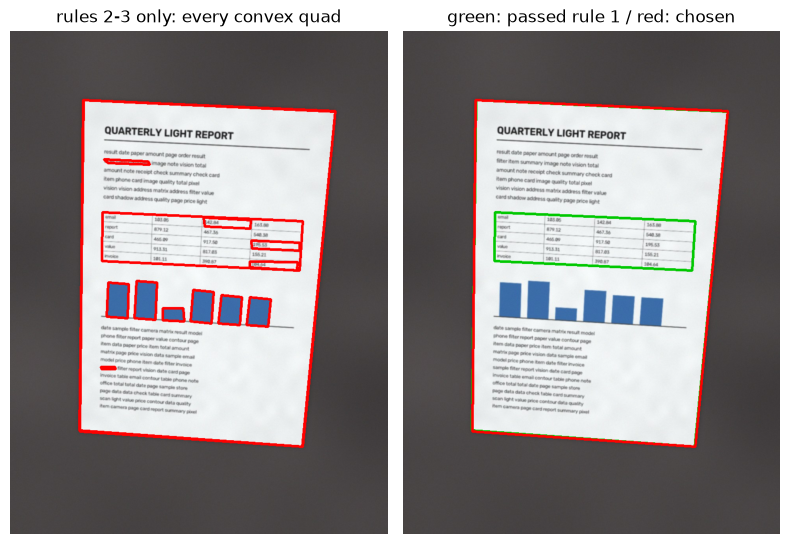

In [11]:
# 규칙 2·3(꼭짓점 4개 + 볼록)만 통과하는 윤곽선을 모은다.
quads_without_area = []
for contour in contours:
    approx = cv2.approxPolyDP(contour, 0.02 * cv2.arcLength(contour, True), True)   # 둘레의 2%보다 작은 굴곡 무시
    if len(approx) == 4 and geometry.is_convex(approx):
        quads_without_area.append(approx)

# 규칙 1–4를 모두 쓴다. 위의 고르기에 넓이 규칙을 더해 묶어 둔 함수다.
params = scanner.ScanParams()      # 기본 설정 묶음: 넓이 5–98%, 다듬기 2% 등
_, candidates, raw_quad, _ = scanner.find_document_quad(closed, params)
print('규칙 2·3만 통과:', len(quads_without_area), '개 / 규칙 1까지 통과:', len(candidates), '개 → 규칙 4로 하나를 고른다')

no_area_rule = work.copy()
cv2.drawContours(no_area_rule, quads_without_area, -1, (0, 0, 255), 3)
all_rules = work.copy()
cv2.drawContours(all_rules, candidates, -1, (0, 200, 0), 3)                     # 초록: 규칙 1 통과
cv2.polylines(all_rules, [raw_quad.astype(np.int32)], True, (0, 0, 255), 4)    # 빨강: 최종 선택
show_images([('rules 2-3 only: every convex quad', no_area_rule),
             ('green: passed rule 1 / red: chosen', all_rules)], columns=2, height=5.5)

**출력 읽기.** 넓이를 따지지 않으면 막대그래프의 막대, 표의 칸까지 볼록 사각형이 여러 개 잡힌다(왼쪽). 넓이 규칙을 통과한 것은 셋뿐이다(오른쪽 초록). 둘은 종이 테두리 선의 바깥쪽과 안쪽을 따라간 윤곽선이고, 하나는 **종이 안의 표**다. 표도 네모나고 볼록하므로 규칙 1–3만으로는 종이와 구별되지 않는다. 그래서 규칙 4(가장 큰 것)가 종이를 고른다(빨강).

"가장 큰 것을 고른다"는 규칙은 배경에 더 큰 사각형 무늬가 있으면 틀린다. 3부의 체크무늬 사진(C02)에서 본다.

### 단계 4. 꼭짓점 순서를 정하고, 직사각형으로 펴기

**풀 문제.** 네 꼭짓점을 찾았다. 네 점을 감싸는 네모로 그냥 잘라 내면 종이가 여전히 비스듬하다. 사진을 늘이고 당겨서 네 꼭짓점이 직사각형의 네 귀퉁이에 오게 해야 한다. 이것을 **투시 변환**이라고 부른다. 비스듬히 찍혀 생긴 원근(먼 쪽이 작게 보이는 현상)을 되돌리는 변환이다.

그 전에 두 가지를 맞춘다.

1. **순서.** "사진 속 이 점은 결과의 왼쪽 위로, 저 점은 오른쪽 위로" 하고 짝을 지어야 한다. 찾은 네 점은 순서가 제멋대로라서, 왼쪽 위 → 오른쪽 위 → 오른쪽 아래 → 왼쪽 아래(TL, TR, BR, BL; 시계 방향)로 정렬한다. 네 점의 중심에서 각 점을 바라보는 각도로 줄 세우고, 오른쪽을 향하는 변을 윗변으로 본다.
2. **원본 좌표로.** 꼭짓점은 작은 사본에서 찾았다. 글자를 선명하게 펴려면 원본에서 펴야 하므로 `scale`로 나눠 되돌린다. 예: 139 ÷ 0.75 = 185.3.

In [12]:
quad_work = geometry.order_points(raw_quad)    # TL, TR, BR, BL 순서로 정렬 (작은 사본 좌표)
quad = quad_work / scale                       # 원본 좌표로 되돌리기

print('찾은 순서 그대로 (작은 사본 좌표):')
print(raw_quad)
names = ['TL 왼쪽 위', 'TR 오른쪽 위', 'BR 오른쪽 아래', 'BL 왼쪽 아래']
table(['꼭짓점', '작은 사본 (x, y)', '원본 (x, y)'],
      [[name, f'({small[0]:.0f}, {small[1]:.0f})', f'({big[0]:.1f}, {big[1]:.1f})']
       for name, small, big in zip(names, quad_work, quad)])

찾은 순서 그대로 (작은 사본 좌표):
[[139. 132.]
 [133. 764.]
 [558. 793.]
 [620. 153.]]


꼭짓점 | 작은 사본 (x, y) | 원본 (x, y)
--- | --- | ---
TL 왼쪽 위 | (139, 132) | (185.3, 176.0)
TR 오른쪽 위 | (620, 153) | (826.7, 204.0)
BR 오른쪽 아래 | (558, 793) | (744.0, 1057.3)
BL 왼쪽 아래 | (133, 764) | (177.3, 1018.7)

투시 변환은 OpenCV 함수 두 개로 한다.

- `cv2.getPerspectiveTransform`: 네 쌍의 짝(사진 속 점 → 결과의 귀퉁이)에서 "사진 속 어느 점이 결과의 어디로 가는가"를 정하는 **규칙(3×3 숫자 표)** 을 구한다. 모르는 숫자 8개를 식 8개(짝 4쌍 × 가로·세로)로 푸는 연립방정식이다.
- `cv2.warpPerspective`: 결과의 모든 점에 그 규칙을 적용해 사진에서 색을 가져온다.

결과 크기는 사진 속 종이의 변 길이로 정한다. 윗변·아랫변 중 긴 쪽이 가로, 왼쪽·오른쪽 변 중 긴 쪽이 세로다. 멀리 있는 변은 짧게 찍히므로 긴 쪽이 실제 길이에 더 가깝다.

**그냥 자르면? 순서를 안 맞추면? 원본 좌표로 안 되돌리면?** 네 가지를 나란히 본다.

결과 크기: 가로 642 × 세로 857


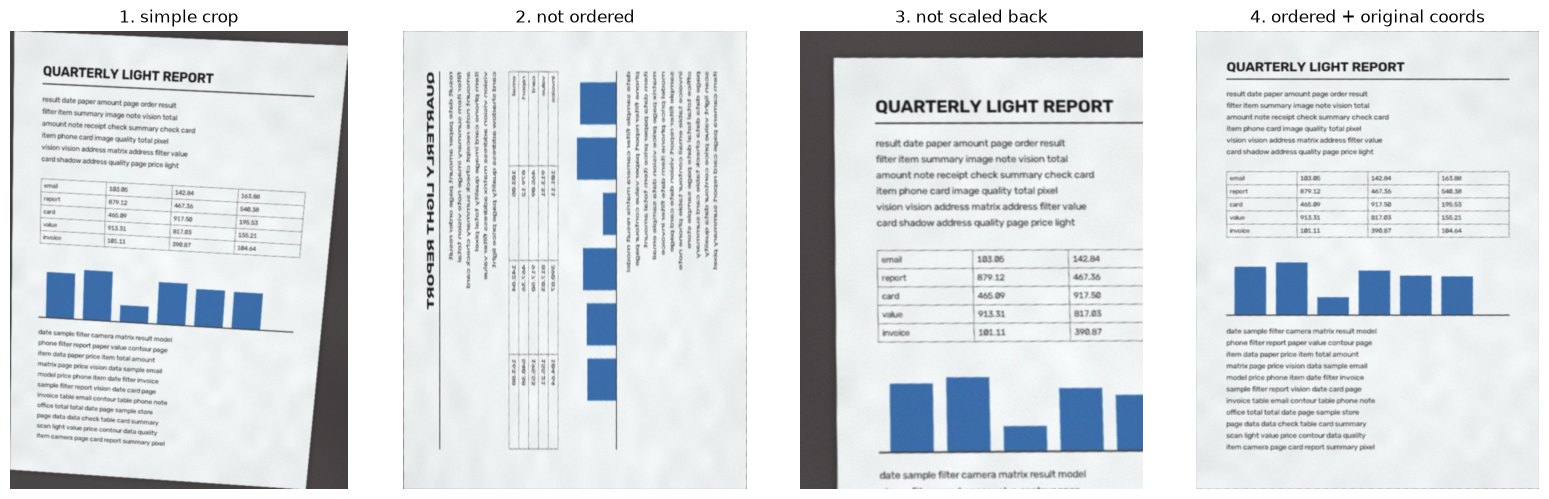

In [13]:
out_width, out_height = geometry.output_size_by_distance(quad)    # 마주 보는 두 변 중 긴 쪽
print('결과 크기: 가로', out_width, '× 세로', out_height)

def flatten(photo, four_points):
    # 사진 속 네 점(TL, TR, BR, BL 순서로 본다)을 결과 직사각형의 네 귀퉁이로 보낸다.
    corners = np.float32([[0, 0], [out_width - 1, 0], [out_width - 1, out_height - 1], [0, out_height - 1]])
    rule = cv2.getPerspectiveTransform(np.float32(four_points), corners)
    return cv2.warpPerspective(photo, rule, (out_width, out_height), flags=cv2.INTER_CUBIC)

x0, y0 = quad.min(axis=0).astype(int)      # 네 점을 감싸는 가장 작은 네모
x1, y1 = quad.max(axis=0).astype(int)
warped = flatten(image, quad)
show_images([('1. simple crop', image[y0:y1, x0:x1]),
             ('2. not ordered', flatten(image, raw_quad / scale)),
             ('3. not scaled back', flatten(image, quad_work)),
             ('4. ordered + original coords', warped)], columns=4, height=5)

**출력 읽기.**

1. **그냥 자르기(simple crop)**: 종이가 여전히 비스듬하고 귀퉁이에 책상이 남는다.
2. **순서를 안 맞춤(not ordered)**: 짝이 어긋나 글자가 옆으로 눕고 거울처럼 뒤집혔다.
3. **원본 좌표로 안 되돌림(not scaled back)**: 작은 사본의 좌표를 큰 원본에 그대로 대서, 종이의 왼쪽 위 일부만 크게 펴졌다.
4. **순서 맞춤 + 원본 좌표**: 종이 네 변이 그림의 네 변과 나란하다.

### 단계 5. 흑백 두 색으로 만들기 (적응형 이진화)

**풀 문제.** 스캐너로 찍은 문서처럼 바탕은 새하얗게, 글자는 새까맣게 만들고 싶다. 모든 점을 흰색(255)이나 검정(0) 둘 중 하나로 바꾸는 일을 **이진화**라고 부른다.

가장 쉬운 방법은 기준 하나를 정하는 것이다. "밝기가 127보다 크면 흰색, 아니면 검정." 그런데 종이에 그림자가 걸치면 그림자 속 흰 종이도 127보다 어둡다.

**해결: 기준을 점마다 다르게.** 점마다 **자기 둘레의 평균 밝기**를 구하고, 그보다 C(여기서는 10)만큼 더 어두우면 글자로 본다.

| 위치 | 둘레 평균 | 기준 (평균 − 10) | 점의 밝기 | 판정 |
| --- | --- | --- | --- | --- |
| 밝은 곳의 종이 | 200 | 190 | 205 | 흰색 |
| 밝은 곳의 글자 | 200 | 190 | 120 | 검정 |
| 그림자 속 종이 | 90 | 80 | 95 | 흰색 |
| 그림자 속 글자 | 90 | 80 | 40 | 검정 |

둘레에 맞춰 기준이 바뀐다고 해서 **적응형 이진화**라고 부른다. C만큼 여유를 두는 것은 바탕이 둘레 평균보다 아주 조금 어둡다고 검정이 되지 않게 하려는 것이다. 그림자가 진하게 걸친 사진 S03으로 두 방법을 비교한다.

방법 | 검은 점의 비율 (%)
--- | ---
기준 하나 (127) | 47.4
적응형 이진화 | 10.5

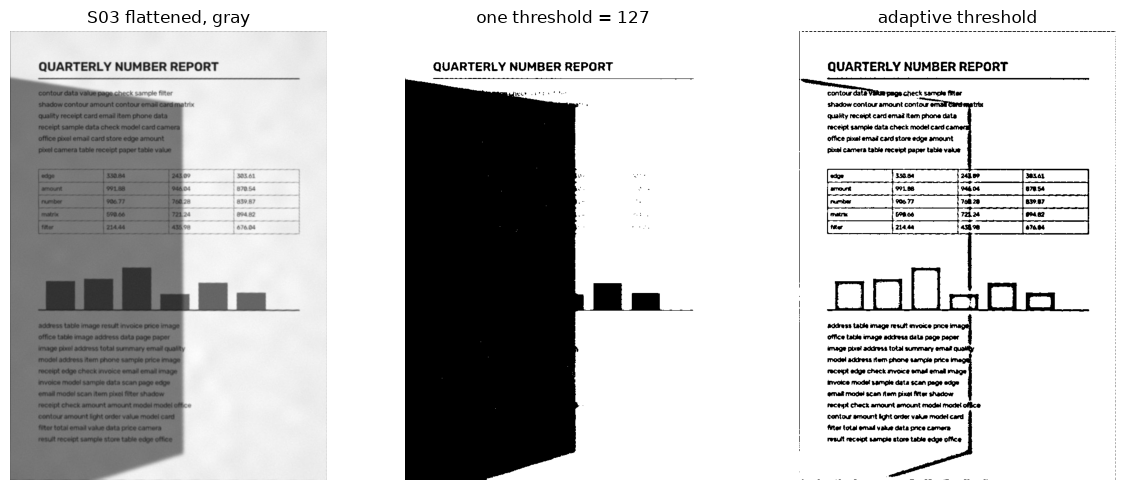

In [14]:
s03_gray_flat = cv2.cvtColor(scanner.scan(s03).warped, cv2.COLOR_BGR2GRAY)   # S03을 1–4단계로 편 흑백 그림

_, one_threshold = cv2.threshold(s03_gray_flat, 127, 255, cv2.THRESH_BINARY)   # 기준 하나(127)
adaptive = cv2.adaptiveThreshold(s03_gray_flat, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
                                 scanner.auto_block_size(s03_gray_flat.shape), 10)   # 둘레 크기, C = 10

# (배열 == 0).mean()은 검정(0)인 칸의 비율이다.
table(['방법', '검은 점의 비율 (%)'],
      [['기준 하나 (127)', round((one_threshold == 0).mean() * 100, 1)],
       ['적응형 이진화', round((adaptive == 0).mean() * 100, 1)]])
show_images([('S03 flattened, gray', s03_gray_flat), ('one threshold = 127', one_threshold),
             ('adaptive threshold', adaptive)], columns=3, height=5)

**출력 읽기.** 기준 하나로 나눈 가운데 그림은 그림자 부분이 통째로 검게 칠해져 그 안의 글자를 읽을 수 없다. 적응형 이진화(오른쪽)는 그림자 속 글자도 읽힌다. 다만 그림자의 가장자리는 가는 선으로 남는다. 그 선을 사이에 두고 밝기가 갑자기 바뀌기 때문이다.

이진화는 이미 편 그림의 색만 바꾼다. 꼭짓점을 잘못 찾아 종이가 잘렸다면 이진화로는 되돌릴 수 없다.

## 2부. 한 줄로 부르기: `scan()`과 앱

1부의 다섯 단계를 `scanner.scan(사진, 설정)` 함수 하나로 묶었다. 앱도 이 함수를 부르고, 단계별 그림을 다섯 창에 띄운다. 0부에서 만든 `result`가 바로 그 결과다.

결과 크기는 앱 기본값으로 **Zhang 방법**을 써서 정한다. 단계 4의 "변 길이" 방법은 종이가 많이 누워 찍히면 가로세로 비율이 틀어진다. Zhang 방법은 네 꼭짓점의 모양에서 카메라가 기운 정도를 계산해 실제 비율을 추정한다. 꼭짓점과 펴는 방법은 같고 결과 크기만 다르다.

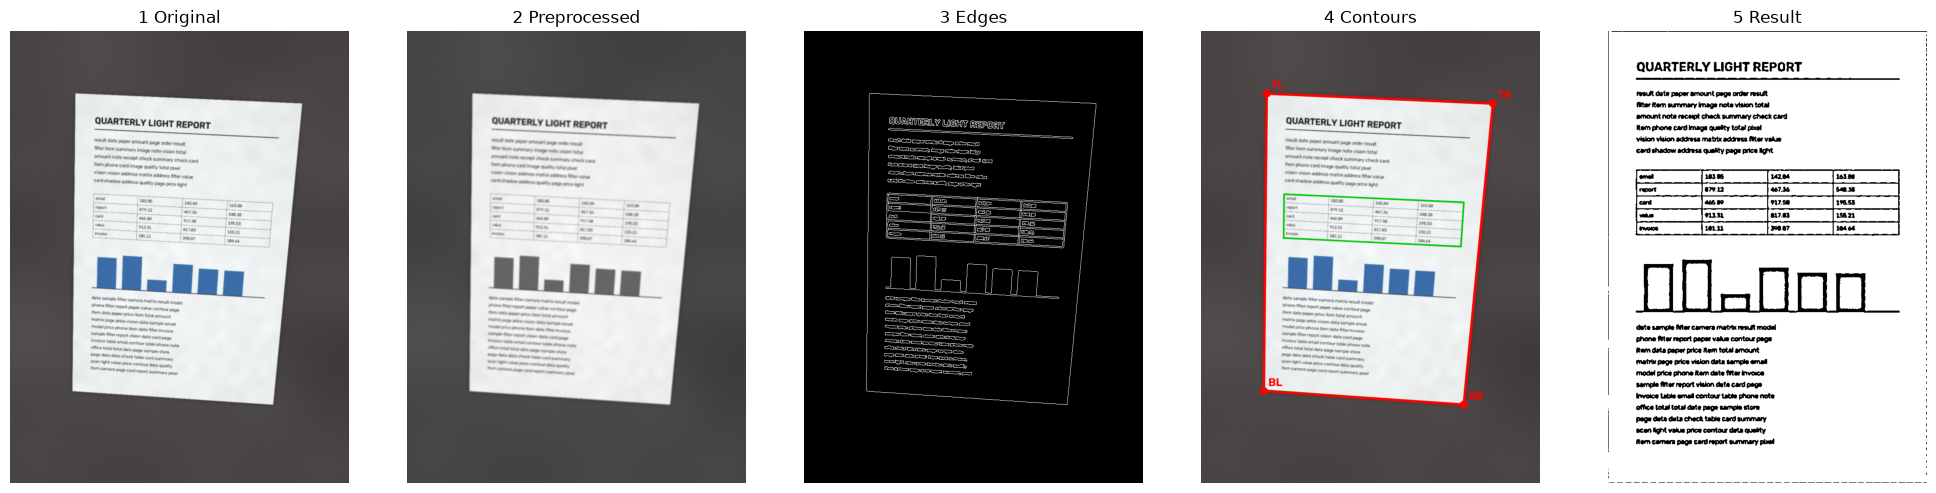

In [15]:
stages = scanner.stage_images(result)    # {창 이름: 그림} 모양의 사전
show_images(list(stages.items()), columns=5, height=5)

**출력 읽기.** 왼쪽부터 앱의 다섯 창이다.

| 창 | 내용 | 1부의 단계 |
| --- | --- | --- |
| 1 Original | 작은 사본 | 1 |
| 2 Preprocessed | 흑백으로 바꾸고 흐리게 한 것 | 1 |
| 3 Edges | Canny 경계선 (닫힘 **전**) | 2 |
| 4 Contours | 초록은 넓이 규칙을 통과한 후보, 빨강은 고른 사각형과 꼭짓점 이름 | 3–4 |
| 5 Result | 편 뒤 이진화한 최종 스캔본 | 4–5 |

**설정 손잡이.** 앱에는 설정을 바꾸는 손잡이(트랙바)가 있다. 한 단계의 설정을 바꾸면 **그 단계와 뒤의 단계만** 바뀌고 앞의 단계는 그대로다.

| 손잡이 | 쓰이는 단계 | 바뀔 수 있는 창 |
| --- | --- | --- |
| Blur Kernel | 1 블러 | 2, 3, 4, 5 |
| Canny Low / High | 2 경계선 | 3, 4, 5 |
| Thresh Block / Thresh C | 5 이진화 | 5만 |

정말 그런지 E01에 설정을 **하나씩만** 바꿔 `scan()`을 부르고 기본 결과와 비교한다. 실행하기 전에 예상해 보자. C를 10에서 20으로 올리면 경계선·꼭짓점·스캔본 중 무엇이 바뀔까?

바꾼 설정 | 달라진 경계선 점 수 | 꼭짓점이 같은가 | 달라진 스캔본 점 수
--- | --- | --- | ---
blur = 11 | 14997 | False | 결과 크기가 달라짐
Canny 150 / 300 | 13560 | True | 0
C = 20 | 0 | True | 11851
block = 81 | 0 | True | 19075

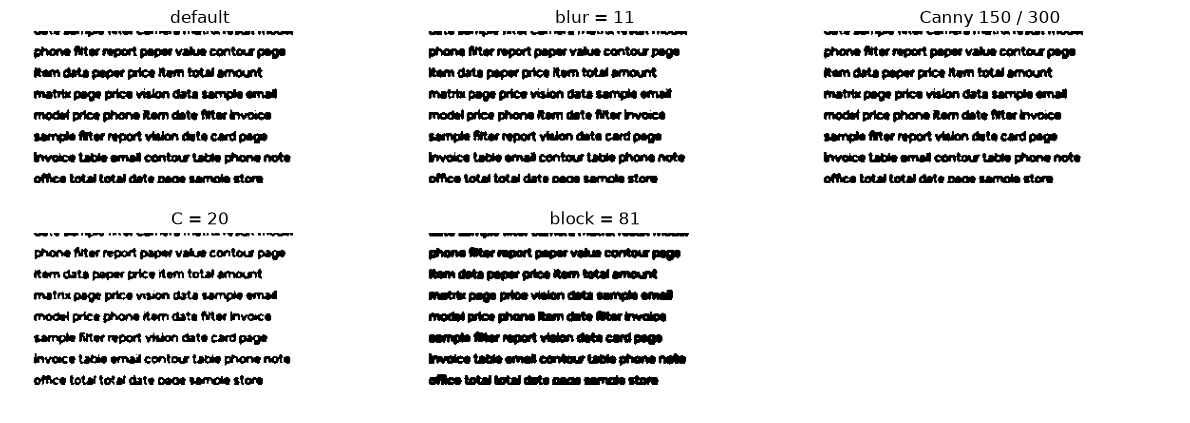

In [16]:
variants = [('blur = 11', replace(params, blur=11)),
            ('Canny 150 / 300', replace(params, canny_low=150, canny_high=300)),
            ('C = 20', replace(params, thresh_c=20)),
            ('block = 81', replace(params, block_size=81))]

change_rows = []
change_pictures = [('default', result.scanned[580:740, 30:430])]   # 본문 글자 부분을 잘라 비교한다
for name, setting in variants:
    changed = scanner.scan(image, setting)
    same_size = changed.scanned.shape == result.scanned.shape
    change_rows.append([name,
                        np.count_nonzero(changed.edges != result.edges),            # 달라진 경계선 점 수
                        np.array_equal(changed.quad, result.quad),                   # 꼭짓점이 같은가
                        np.count_nonzero(changed.scanned != result.scanned) if same_size else '결과 크기가 달라짐'])
    change_pictures.append((name, changed.scanned[580:740, 30:430]))

table(['바꾼 설정', '달라진 경계선 점 수', '꼭짓점이 같은가', '달라진 스캔본 점 수'], change_rows)
show_images(change_pictures, columns=3, height=2.2)

**출력 읽기.**

- **blur = 11**: 경계선이 크게 바뀌고 꼭짓점도 1픽셀쯤 움직여 결과 크기까지 바뀌었다. 앞 단계를 바꾸면 뒤가 모두 따라 바뀐다.
- **Canny 150 / 300**: 경계선은 크게 바뀌었지만 꼭짓점과 스캔본은 그대로다. 종이 테두리는 기울기가 아주 커서 기준을 올려도 살아남았다. 경계선이 바뀐다고 결과가 늘 바뀌는 것은 아니다.
- **C = 20, block = 81**: 경계선과 꼭짓점은 그대로이고 스캔본만 바뀌었다. 그림에서 C = 20은 글자 획이 가늘어지고 block = 81은 조금 굵어진다.

**`found=True`는 "성공"이 아니다.** `scan()`은 규칙을 통과한 사각형이 있으면 `found=True`를 돌려준다. 그 사각형이 진짜 종이인지는 모른다. 단계 2의 E03도 파란 띠를 빼먹었지만 `found=True`였다. 맞게 찾았는지는 정답과 비교해야 안다. 3부에서 한다.

## 3부. 사진 20장으로 성적 매기기

**풀 문제.** E01은 잘 됐다. 하지만 한 장으로 "이 스캐너는 잘 된다"고 말할 수 없다. 여러 장에 **같은 설정**을 쓰고 **같은 기준**으로 성적을 매겨야 한다.

**정답이 있는 사진.** 이 미션의 사진 20장은 컴퓨터로 만든 **합성 사진**이다. 종이를 어디에 어떤 각도로 놓을지 정해서 그렸기 때문에 네 꼭짓점의 정확한 위치(정답)를 안다. 네 가지 조건에 5장씩이고, 이름의 첫 글자가 조건이다.

| 글자 | 조건 |
| --- | --- |
| E (easy) | 단순한 배경, 거의 정면 |
| S (shadow) | 그림자, 어두운 조명, 빛 반사 |
| T (tilt) | 45도 넘게 기울여 찍음 |
| C (complex) | 복잡한 배경 |

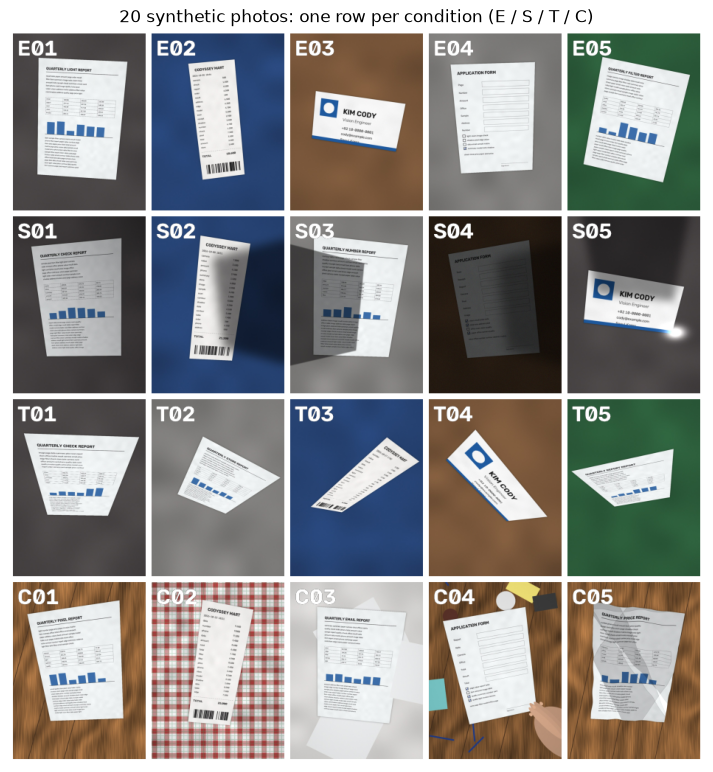

In [17]:
dataset = evaluate.load_dataset(root / 'data/synthetic')    # (정답 정보, 사진) 쌍 20개
# 20장을 한 장으로 이어 붙여 본다. 한 줄에 한 조건(E, S, T, C) 5장씩이다.
tiles = []
for label, photo in dataset:
    tile = cv2.resize(photo, (180, 240), interpolation=cv2.INTER_AREA)
    tile = cv2.copyMakeBorder(tile, 4, 4, 4, 4, cv2.BORDER_CONSTANT, value=(255, 255, 255))   # 사진 사이 흰 틈
    for color, thickness in [((0, 0, 0), 5), ((255, 255, 255), 2)]:       # 검은 테두리를 두른 흰 글자
        cv2.putText(tile, label['id'], (10, 34), cv2.FONT_HERSHEY_SIMPLEX, 1.0, color, thickness)
    tiles.append(tile)
montage = np.vstack([np.hstack(tiles[i:i + 5]) for i in range(0, 20, 5)])

fig, axis = plt.subplots(figsize=(9, 9.5))
axis.imshow(cv2.cvtColor(montage, cv2.COLOR_BGR2RGB))
axis.axis('off')
axis.set_title('20 synthetic photos: one row per condition (E / S / T / C)')
plt.show()

**채점 규칙.**

1. 네 꼭짓점마다 찾은 점과 정답 점 사이의 거리를 잰다.
2. 그중 **가장 큰 거리**를 고른다. 한 점이라도 크게 틀리면 결과가 망가지기 때문이다.
3. 그 거리를 **종이의 대각선 길이**로 나눈다. 같은 10픽셀 오차라도 작은 명함에서는 큰 실수이고 큰 A4에서는 작은 실수다.
4. 이 비율이 **2% 이하면 성공**, **5% 이하면 부분 성공**, 그보다 크거나 종이를 못 찾으면 **실패**다.

정답은 채점할 때만 쓴다. 종이를 찾는 `scan()`에는 넘기지 않는다. 20장 모두 기본 설정으로 `scan()`을 돌려 채점한다.

In [18]:
# rows는 사진마다 성적표 한 줄(사전), results는 사진마다 scan()의 결과 묶음이다.
rows, results = evaluate.evaluate(dataset, params, warp=True)
korean = {'success': '성공', 'partial': '부분 성공', 'fail': '실패'}

table(['조건', '사진 수', '성공', '부분 성공', '실패'],
      [[s['name'], s['n'], s['success'], s['partial'], s['fail']] for s in evaluate.summarize(rows)])

# 성공하지 못한 사진만 따로 본다.
miss_rows = []
for row, (label, _) in zip(rows, dataset):
    if row['status'] != 'success':
        ratio = f"{row['error_ratio'] * 100:.2f}" if row['found'] else '-'
        miss_rows.append([row['id'], label['note'], '찾음' if row['found'] else '못 찾음', ratio, korean[row['status']]])
table(['사진', '어떤 사진인가', '사각형', '가장 큰 오차 ÷ 대각선 (%)', '판정'], miss_rows)

조건 | 사진 수 | 성공 | 부분 성공 | 실패
--- | --- | --- | --- | ---
단순 배경 + 정면 | 5 | 4 | 1 | 0
그림자 있음 | 5 | 3 | 0 | 2
45도 이상 기울어짐 | 5 | 4 | 1 | 0
복잡한 배경 | 5 | 1 | 0 | 4
전체 | 20 | 12 | 2 | 6

사진 | 어떤 사진인가 | 사각형 | 가장 큰 오차 ÷ 대각선 (%) | 판정
--- | --- | --- | --- | ---
E03 | 갈색 책상 위 명함 | 찾음 | 3.63 | 부분 성공
S04 | 저조도 | 못 찾음 | - | 실패
S05 | 코팅 명함의 빛 반사 | 못 찾음 | - | 실패
T04 | 48° 기울기, 좌우 25°, 평면 회전 45° | 찾음 | 2.29 | 부분 성공
C02 | 체크무늬 식탁보 | 찾음 | 48.73 | 실패
C03 | 흰 책상 위 다른 종이와 겹침 (배경 대비 낮음) | 못 찾음 | - | 실패
C04 | 잡동사니 책상, 손가락이 모서리를 가림 | 찾음 | 6.22 | 실패
C05 | 구겨진 A4, 나뭇결 책상 | 못 찾음 | - | 실패

**출력 읽기.** 20장 중 **성공 12, 부분 성공 2, 실패 6**이다. 성공률 60%다.

- 단순한 배경(E)과 기울어진 사진(T)은 테두리만 뚜렷하면 잘 찾는다. 부분 성공 두 장(E03, T04)은 모두 파란 띠가 있는 명함이다.
- 그림자(S)와 복잡한 배경(C)에서 실패가 몰렸다.

실패는 두 종류다. **못 찾음**(S04, S05, C03, C05)과 **찾았지만 틀림**(C02, C04)이다. 이 60%는 이 합성 사진 20장에서 잰 수치이고, 실제 휴대폰 사진에서의 성공률은 따로 재야 한다.

**실패한 사진을 눈으로 보기.** 성공한 E01과 실패한 S05, C02, C05를 나란히 본다. 초록 선이 정답, 빨간 선이 찾은 사각형이다.

E01 (회색 책상 위 A4 보고서): 성공 
S05 (코팅 명함의 빛 반사): 실패 / 면적 조건을 만족하는 닫힌 윤곽선 없음
C02 (체크무늬 식탁보): 실패 
C05 (구겨진 A4, 나뭇결 책상): 실패 / 큰 윤곽선은 있으나 볼록 사각형이 아님 (꼭짓점 수 [7, 9])


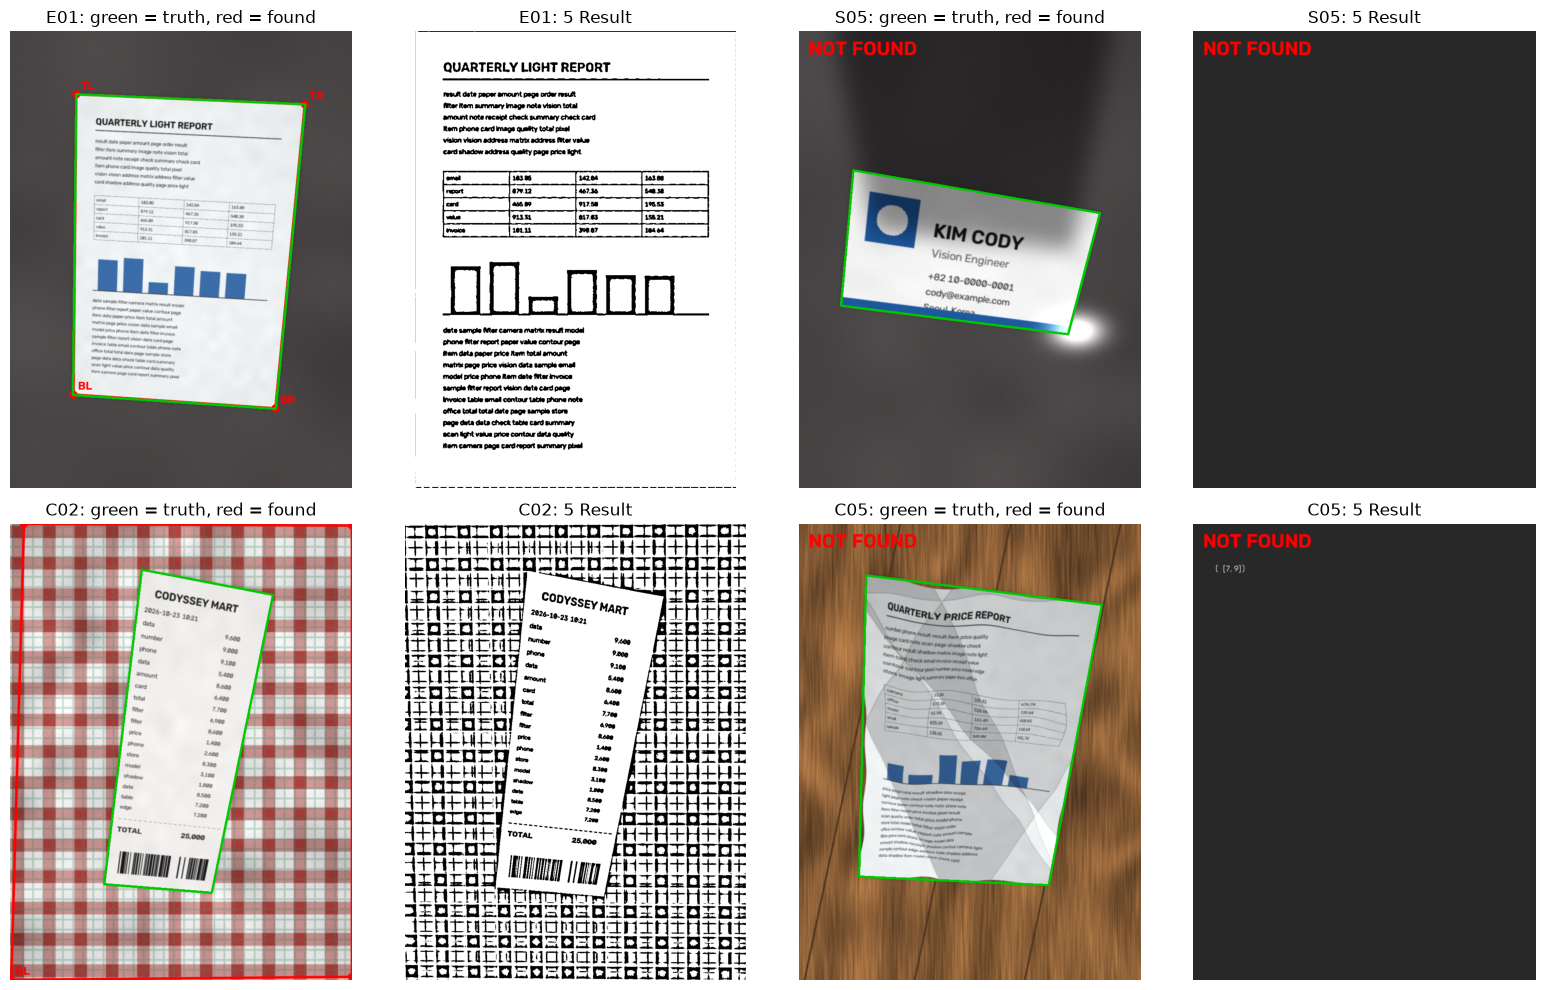

In [19]:
by_id = {row['id']: (label, row, processed) for (label, _), row, processed in zip(dataset, rows, results)}

case_pictures = []
for case_id in ['E01', 'S05', 'C02', 'C05']:
    label, row, processed = by_id[case_id]
    overlay = scanner.draw_contours(processed, show_candidates=False)                 # 빨강: 찾은 사각형
    truth_small = np.rint(np.array(label['corners']) * processed.scale).astype(np.int32)
    cv2.polylines(overlay, [truth_small], True, (0, 200, 0), 3)                       # 초록: 정답
    case_pictures.append((f'{case_id}: green = truth, red = found', overlay))
    case_pictures.append((f'{case_id}: 5 Result', scanner.stage_images(processed)['5 Result']))
    print(f"{case_id} ({label['note']}): {korean[row['status']]}", f"/ {row['reason']}" if row['reason'] else '')
show_images(case_pictures, columns=4, height=5)

**출력 읽기.** 사진마다 두 장씩이다. 왼쪽은 정답(초록)과 찾은 사각형(빨강), 오른쪽은 최종 결과다.

- **E01**: 초록과 빨강이 겹친다. 성공이다.
- **S05(빛 반사가 있는 명함)**: 반사 때문에 명함 테두리가 닫힌 덩어리로 이어지지 않아 넓이 규칙을 통과한 윤곽선이 없다. 못 찾음이다.
- **C02(체크무늬 식탁보 위 영수증)**: 빨간 사각형이 영수증이 아니라 **사진 거의 전체**를 감쌌다. 체크무늬 선도 경계선으로 잡혀 영수증보다 큰 사각형이 생겼고, 규칙 4(가장 큰 것)가 그것을 골랐다. 결과 그림은 반듯해 보이지만 영수증이 아니다. `found=True`인데 실패다.
- **C05(구겨진 종이)**: 큰 윤곽선은 있지만 구김 선이 테두리에 이어져 다듬어도 꼭짓점이 4개로 줄지 않는다. 규칙 2에서 걸렸다.

## 4부. 설정을 바꾸거나 규칙을 더하면 고쳐질까?

**풀 문제.** 실패한 사진을 보면 "설정이 나빠서 그런 것 아닌가?"라는 생각이 든다. 가장 확실하게 답하는 방법은 **가능한 설정을 모두 해 보는 것**이다.

종이 찾기에 가장 큰 영향을 주는 세 숫자를 바꾼다. 블러 크기 7가지(1, 3, …, 13; 1은 블러 없음), Canny low 7가지, high 7가지다. 모두 짝지으면 343가지이고, low가 high보다 작은 266가지만 쓴다. 20장 × 266가지 = 5,320번 종이를 찾는다.

몇 분 걸리는 계산이라, 같은 함수(`evaluate.parameter_sweep`)로 미리 돌려 저장해 둔 결과(`outputs/sweep_matrix.npz`)를 읽는다. 직접 다시 돌리려면 `RECOMPUTE = True`로 바꾼다.

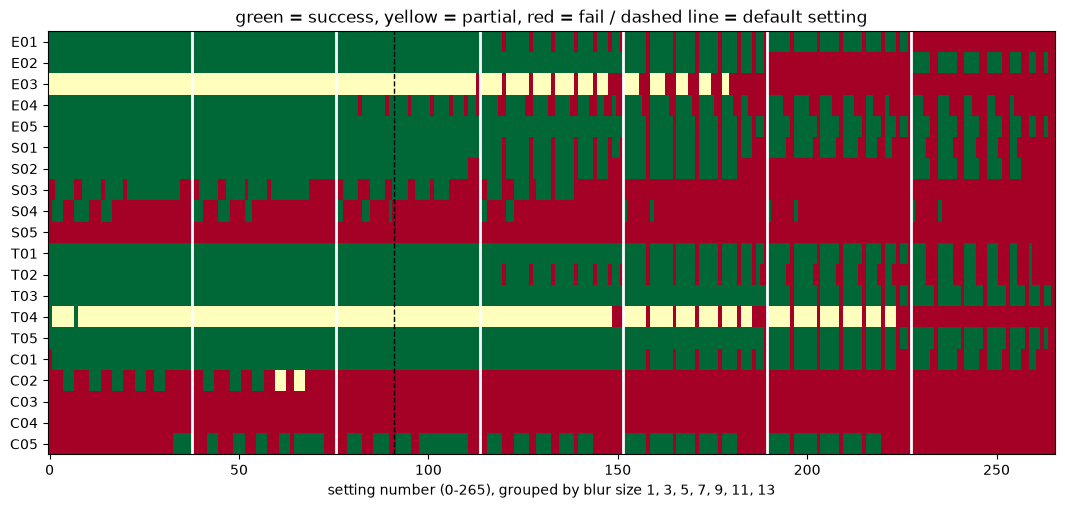

In [20]:
RECOMPUTE = False

if RECOMPUTE:
    configs, matrix, ids = evaluate.parameter_sweep(dataset, params)
else:
    saved = np.load(root / 'outputs/sweep_matrix.npz')
    configs = [tuple(int(v) for v in config) for config in saved['configs']]   # (블러, low, high) 266개
    matrix = saved['matrix']                                                  # (사진 20, 설정 266). 2 성공 / 1 부분 / 0 실패
    ids = [str(name) for name in saved['ids']]

fig, axis = plt.subplots(figsize=(13, 5.5))
axis.imshow(matrix, aspect='auto', cmap='RdYlGn', vmin=0, vmax=2, interpolation='nearest')
axis.set_yticks(range(len(ids)))
axis.set_yticklabels(ids)
axis.set_xlabel('setting number (0-265), grouped by blur size 1, 3, 5, 7, 9, 11, 13')
axis.set_title('green = success, yellow = partial, red = fail / dashed line = default setting')
axis.axvline(configs.index((5, 50, 150)), color='black', linestyle='--', linewidth=1)
for boundary in range(38, 266, 38):            # 블러 크기 하나에 설정이 38개씩이다
    axis.axvline(boundary - 0.5, color='white', linewidth=2)
plt.show()

**그림 읽기.** 가로 한 줄이 사진 한 장, 세로 한 칸이 설정 하나다. 흰 세로선은 블러 크기의 경계이고, 점선이 기본 설정이다.

- 가로줄이 대부분 초록인 사진(T03, T05 등)은 설정을 크게 가리지 않는다.
- 가로줄에 초록이 하나도 없는 사진은 어떤 설정을 써도 성공하지 못한다.
- 블러가 큰 오른쪽 묶음으로 갈수록 빨강이 늘어난다. 너무 흐리게 하면 테두리까지 뭉개진다.
- **위에서 아래까지 전부 초록인 세로 칸은 하나도 없다.**

숫자로 정리한다.

In [21]:
sweep = evaluate.sweep_summary(configs, matrix, ids)
table(['방법', '성공한 사진 (20장 중)'],
      [['기본 설정 (5, 50, 150)', sweep['default']['success']],
       ['20장 전체에 가장 좋은 설정 하나', sweep['best']['success']],
       ['사진마다 가장 좋은 설정을 따로 고름 (정답을 보고 고른 상한)', sweep['oracle_success']]])
print('어떤 설정으로도 성공하지 못한 사진:', sweep['never_success'])

방법 | 성공한 사진 (20장 중)
--- | ---
기본 설정 (5, 50, 150) | 12
20장 전체에 가장 좋은 설정 하나 | 14
사진마다 가장 좋은 설정을 따로 고름 (정답을 보고 고른 상한) | 16

어떤 설정으로도 성공하지 못한 사진: ['E03', 'S05', 'C03', 'C04']


**출력 읽기.** 가장 좋은 설정 하나를 골라도 기본값보다 2장 더 성공할 뿐이다. 셋째 줄은 정답을 미리 보고 사진마다 맞는 설정을 고른 경우라 실제로는 쓸 수 없는데, 그래도 16장이 한계다. 네 장은 266가지 어느 것으로도 성공하지 못했다.

**왜 설정 하나로는 안 되나: 서로 반대를 원하는 두 사진.** 어두운 사진 S04와 체크무늬 사진 C02를 본다. 블러 크기별로, 각 사진이 성공한 설정의 Canny high 값을 모은다.

S04 성공 설정 33 개 / C02 성공 설정 24 개 / 둘 다 성공 0 개


블러 크기 | S04(어두운 사진)가 성공한 Canny high | C02(체크무늬)가 성공한 Canny high
--- | --- | ---
1 | [50, 100, 150, 200] | [250, 300, 400]
3 | [50, 100, 150] | [200, 250, 300]
5 | [50, 100] | 없음
7 | [50, 100] | 없음
9 | [50] | 없음
11 | [50] | 없음
13 | [50] | 없음

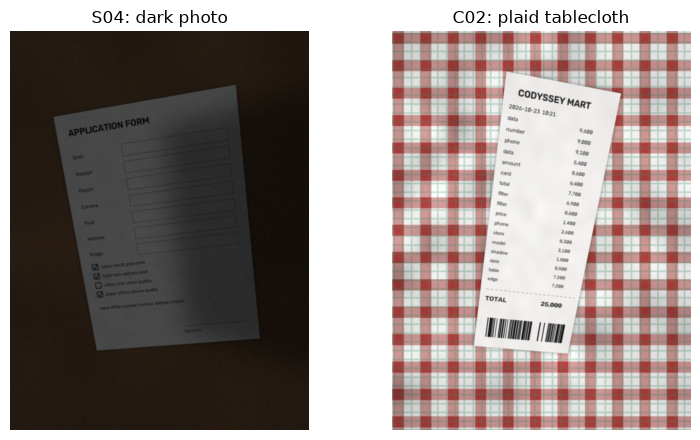

In [22]:
dark_ok = matrix[ids.index('S04')] == 2      # S04가 성공한 설정인가? (266칸의 참/거짓)
plaid_ok = matrix[ids.index('C02')] == 2     # C02가 성공한 설정인가?
print('S04 성공 설정', dark_ok.sum(), '개 / C02 성공 설정', plaid_ok.sum(), '개 / 둘 다 성공', (dark_ok & plaid_ok).sum(), '개')

pair_rows = []
for blur_size in evaluate.SWEEP_BLUR:
    dark_highs = sorted({configs[j][2] for j in np.flatnonzero(dark_ok) if configs[j][0] == blur_size})
    plaid_highs = sorted({configs[j][2] for j in np.flatnonzero(plaid_ok) if configs[j][0] == blur_size})
    pair_rows.append([blur_size, dark_highs or '없음', plaid_highs or '없음'])
table(['블러 크기', 'S04(어두운 사진)가 성공한 Canny high', 'C02(체크무늬)가 성공한 Canny high'], pair_rows)

show_images([('S04: dark photo', by_id['S04'][2].work), ('C02: plaid tablecloth', by_id['C02'][2].work)],
            columns=2, height=4.5)

**출력 읽기.** 두 사진이 **함께 성공하는 설정은 0개**다. 같은 블러 크기 안에서 S04는 high가 낮을 때만, C02는 high가 높을 때만 성공한다.

- **S04(어두운 사진)** 는 종이와 배경의 밝기 차이가 작다. 기준을 **낮춰야** 테두리가 경계선으로 잡힌다.
- **C02(체크무늬)** 는 무늬의 선이 영수증 테두리만큼 뚜렷하다. 기준을 **높여야** 무늬가 사라진다.

Canny 기준 하나에 "종이 테두리는 남기고 배경 무늬는 지우는" 일을 맡겼는데, 둘 중 어느 쪽이 더 뚜렷한지가 사진마다 다르다. 그래서 시험한 범위 안에서는 숫자 하나로 두 사진을 모두 맞출 수 없었다.

**규칙을 더하면?** 숫자 조절로 안 된다면, 실패 원인마다 대책 규칙을 만들어 더해 본다.

| 이름 | 바꾼 것 | 노린 실패 |
| --- | --- | --- |
| V1 | 닫힘을 뺀다 | 닫힘이 구김 선을 테두리에 이어 붙이는 경우 |
| V2 | 파랑·초록·빨강 각각에서 경계선을 찾아 합친다 | 흑백으로 바꾸면 밝기가 비슷해져 사라지는 색 경계 |
| V3 | Canny 기준을 사진의 밝기에 맞춰 자동으로 정한다 | 어두운 사진 |
| V4 | 블러 전에 어두운 곳의 밝기 차이를 키운다 (CLAHE) | 어두운 사진 |
| V5 | 다듬을 때 무시할 굴곡을 2배로 한다 | 꼭짓점이 4개로 줄지 않는 경우 |
| V6 | V2–V5를 모두 켠다 | 전부 |

In [23]:
rules = evaluate.rule_experiment(dataset, params)    # 규칙마다 20장을 다시 채점한다
table(['규칙', '성공 (20장 중)', '새로 성공한 사진', '성공에서 밀려난 사진'],
      [[r['name'], r['success'], ', '.join(r.get('fixed', [])) or '-', ', '.join(r.get('broken', [])) or '-']
       for r in rules])

규칙 | 성공 (20장 중) | 새로 성공한 사진 | 성공에서 밀려난 사진
--- | --- | --- | ---
V0 기본 규칙 | 12 | - | -
V1 닫힘 연산 제거 | 13 | C05 | -
V2 + 색 채널별 엣지 | 15 | E03, S04, T04 | -
V3 + 자동 Canny 임계값 | 13 | S04 | -
V4 + CLAHE 대비 향상 | 13 | S04 | -
V5 + 근사 허용 오차 2배 | 12 | - | -
V6 V2~V5 모두 | 15 | E03, S04, T04 | -

**출력 읽기.**

- **V2(색마다 경계선)** 가 가장 효과가 크다. 12장에서 15장으로 늘었다. 명함 E03·T04의 파란 띠는 흑백으로 바꾸면 책상과 밝기가 비슷해지는데, 색을 따로 보면 띠의 경계가 잡힌다.
- **V3, V4**는 어두운 S04 하나를 고친다. **V1**은 구겨진 C05를 고친다. 대신 닫힘이 없으면 명함 E03·T04의 테두리가 닫히지 않아 부분 성공에서 실패로 떨어진다. 이 표는 성공이던 사진만 "밀려남"으로 세므로 여기에는 나오지 않는다.
- **V6(모두)** 도 15장이다. 규칙을 다 더해도 5장이 남는다.

규칙은 **자기가 노린 실패만** 고쳤다. 체크무늬(C02), 흰 책상 위 흰 종이(C03), 손가락에 가려진 모서리(C04), 빛 반사(S05)는 그대로다. 이런 사진에서는 "여러 선 가운데 어느 것이 종이 테두리인가"를 판단해야 하는데, 밝기 차이와 사각형 모양만 보는 규칙으로는 그 판단을 할 수 없다.

## 정리

| 시도 | 성공 (20장 중) |
| --- | --- |
| 기본 설정 | 12 |
| 20장 전체에 가장 좋은 설정 하나 | 14 |
| 사진마다 가장 좋은 설정을 따로 고름 (정답을 보고 고른 상한) | 16 |
| 기본 설정 + 대책 규칙 | 15 |

- 사람이 정한 규칙(밝기가 크게 바뀌는 곳이 경계, 가장 큰 볼록 사각형이 문서)만으로도 테두리가 뚜렷한 사진은 반듯하게 편다.
- 사진마다 필요한 기준이 서로 반대여서, 시험한 범위 안에서는 설정 하나로 모든 사진을 맞출 수 없었다.
- 규칙을 더해도 "어느 선이 종이 테두리인가"를 판단해야 하는 사진은 남는다. 다음에 시도해 볼 방향은 사진과 정답을 많이 보여 주고 기준을 스스로 익히게 하는 것(학습)이다. 그 방법이 정말 더 나은지는 따로 실험해야 안다.

**앱으로 직접 해 보기.** A3-1 폴더에서 실행하면 다섯 창과 손잡이가 뜬다. `s`는 저장, `q`는 끝내기다. 파일 이름을 `S05.jpg`, `C02.jpg`로 바꾸면 두 종류의 실패를 볼 수 있다.

```powershell
uv run python -m src.app data/synthetic/E01.jpg
```

창을 띄울 수 없는 환경에서는 `--no-gui --out outputs/cli`를 붙이면 단계별 그림이 파일로 저장된다.

**스스로 설명해 보기.**

1. 종이는 작은 사본에서 찾는데, 왜 펴는 것은 원본에서 하나? `scale`로 나누지 않으면 어떻게 되나? (단계 4)
2. Canny의 기준은 왜 두 개인가? (단계 2)
3. 볼록 사각형이 여러 개면 무엇을 고르나? 그 규칙이 C02에서는 왜 문제가 됐나? (단계 3, 3부)
4. `found=True`와 "성공"은 어떻게 다른가? (2부, 3부)
5. Thresh C를 바꿔도 C02의 실패가 고쳐지지 않는 이유는? (2부)
6. S04와 C02를 설정 하나로 함께 성공시킬 수 없었던 이유는? (4부)

각 단계의 계산(흑백 가중합, 블러, 투시 변환 연립방정식, 적응형 이진화)을 숫자로 직접 따라가 보려면 같은 폴더의 `scanner_walkthrough.ipynb`를 연다.